# Прогнозирование поведения клиента (ДЗ)

Привет!

В этом домашнем задании тебе предстоит построить кривые def rate, внедрить def rate в NPV-модель и исследовать зависимость обновленной модели от выбранного скора (подробные пункты перечислены ниже).

Для выполнения тебе понадобится выборка с данными, которую использовали на семинаре (**data_vintages.csv**), x_score и PD (**data_scores.csv**). Не бойся выходить за рамки методов, предлженных в лекции.

Главное - не забывай **аргументировать** свой выбор и давать **комментарии** своим действиям. 

Удачи!

#### Как будет оцениваться работа:
За это ДЗ ты можешь получить максимум **10 баллов**. Все пункты весят по-разному, баллы указаны рядом с пунктами. Баллы могут сниматься в случае неполного выполнения задания или отсутствия аргументации.


#### Задачи:

1) Построить кривые DEF rate (5 баллов)
    - Выбрать переменную для разбивки по бакетам (0.5 балла)
    - Провести анализ поколений (0.5 балла)
    - Построить винтажи DEF rate (0.5 балла)
    - Провести анализ на особые точки (0.5 балла)
    - Провести анализ наличия внешних воздействий и при необходимости вычистить кривые (2 балла)
    - Построить среднее по винтажам для каждого бакета (0.5 балла)
    - Сгладить кривые (0.5 балла)
    
2) Внести в модель построенную кривую DEF rate и исследовать зависимость от скора (5 баллов)
    - Реализовать метод для расчета DEF rate по поданному скору (3 балла)
    - Рассчитать NPV для кредита с заданными параметрами (1 балл)
    - Построить кривую зависимости NPV от скора (1 балл)
    
**Пожалйуста, аргументируйте свои решения по каждому пункту**

В качестве результата приложи текущий ноутбук с названием 'Surname_def.ipynb'

## Кривые DEF rate

#### Выгружаем данные с винтажами

In [1]:
# В качестве данных для винтажей используй файл с семинара data_vintages.csv
import pandas as pd

# код с семинара.
df = pd.read_csv(
    "data_vintages.csv",
    sep=";",
    encoding="cp1251",
    index_col=0,
    parse_dates=["gen_month_dt", "gen_quarter_dt"],
)
df.head(10)

,user_id,statement_num,gen_month_dt,gen_quarter_dt,clo_flg,def_flg,dlq_flg,act_flg,prev_clo_flg,prev_def_flg,prev_dlq_flg,prev_act_flg
0,127336,19,2019-07-01,2019-07-01,0,0,0,1,0,0,0,1
1,35907,16,2019-04-01,2019-04-01,1,0,0,0,1,0,0,0
2,45228,21,2019-05-01,2019-04-01,0,0,0,1,0,0,0,1
3,39035,23,2019-07-01,2019-07-01,0,0,0,1,0,0,0,1
4,130780,19,2019-08-01,2019-07-01,1,0,0,0,1,0,0,0
5,13089,14,2019-03-01,2019-01-01,0,0,0,1,0,0,0,1
6,132017,7,2019-08-01,2019-07-01,1,0,0,0,1,0,0,0
7,67966,24,2019-06-01,2019-04-01,1,0,0,0,1,0,0,0
8,152759,11,2019-11-01,2019-10-01,0,0,1,1,0,0,0,1
9,128462,20,2019-08-01,2019-07-01,1,0,0,0,1,0,0,0


#### Выгружаем данные со скорами для дальнейшей разбивки на бакеты

In [2]:
# Тебе понадобятся два скора: 
# 1) x_score из файла data_scores.csv 
# 2) PD (вероятность дефолта за 12 месяцев), который вы получили в предыдущем ДЗ

# кажется, в предыдущем дз мы не 
# получали никаких PD как данные 
# и не строили их сами, так как 
# считали чисто NPV, поэтому считаем,
# что PD тоже из файла.

# код с семинара.
df_scores = pd.read_csv(
    "data_scores.csv", sep=";", encoding="cp1251", decimal=",", index_col=0
)

df_scores.head(10)

,user_id,pd,x_score
0,9311,0.035025,0.219980
1,155026,0.046279,0.146986
2,17584,0.007221,0.343298
3,156231,0.069679,0.186684
4,123587,0.010402,0.305582
5,125519,0.032667,0.261228
6,123890,0.027963,0.199389
7,82137,0.073694,0.113313
8,55227,0.011746,0.335474
9,124825,0.049237,0.227262


#### Бъем выборку на бакеты и джойним с данными с винтажами

In [3]:
# Разбей данные на бакеты по каждой переменной (базовый набор бакетов - 3)
import numpy as np

# код с семинара.
df_scores = df_scores.sort_values(["pd"], ignore_index=True)
df_scores["pd_bucket"] = np.minimum(df_scores.index // (df_scores.shape[0] // 3), 2)
print(df_scores.groupby(["pd_bucket"])["pd"].mean())

df_scores = df_scores.sort_values(["x_score"], ignore_index=True)
df_scores["x_bucket"] = np.minimum(df_scores.index // (df_scores.shape[0] // 3), 2)
print(df_scores.groupby(["x_bucket"])["x_score"].mean())

df = df.merge(
    df_scores[["user_id", "pd_bucket", "x_bucket", "pd", "x_score"]],
    how="left",
    on="user_id",
).dropna()


df.head()

pd_bucket
0    0.011040
1    0.032685
2    0.068209
Name: pd, dtype: float64
x_bucket
0    0.133270
1    0.220838
2    0.379452
Name: x_score, dtype: float64


,user_id,statement_num,gen_month_dt,gen_quarter_dt,clo_flg,def_flg,dlq_flg,act_flg,prev_clo_flg,prev_def_flg,prev_dlq_flg,prev_act_flg,pd_bucket,x_bucket,pd,x_score
0,127336,19,2019-07-01,2019-07-01,0,0,0,1,0,0,0,1,1,2,0.021296,0.469410
1,35907,16,2019-04-01,2019-04-01,1,0,0,0,1,0,0,0,2,0,0.064742,0.157215
2,45228,21,2019-05-01,2019-04-01,0,0,0,1,0,0,0,1,0,2,0.018490,0.469583
3,39035,23,2019-07-01,2019-07-01,0,0,0,1,0,0,0,1,1,1,0.025882,0.210896
4,130780,19,2019-08-01,2019-07-01,1,0,0,0,1,0,0,0,1,1,0.024330,0.269492


### Выбери переменную, которая делит кривые наилучшим образом (0.5 баллов)

 Из двух скоров (x_score и ваш PD) выбери тот, который разделяет кривые наилучшим образом

Из лекции мы помним, что $\text{def\_rate}_n = \frac{\# DEF_n - \# DEF_{n - 1}}{\# ACT_{n-1}}$. У нас в данных есть флажки не только для текущих статусов, но и для предыдущих, поэтому будем использовать ```prev_def_flg``` и ```prev_act_flg```, чтобы всё корректно посчитать.

In [4]:
def plot_def_rate_by_bucket(df, bucket):
#     код функции
    return (
        df.groupby([bucket, "statement_num"])
        .agg({'def_flg': 'sum', 'prev_def_flg' : 'sum', 'prev_act_flg' : 'sum'})
        .rename(
            columns=({"def_flg": "def_cnt", "prev_def_flg": "prev_def_cnt", "prev_act_flg": "prev_act_cnt"})
        )
        .eval("def_rate = (def_cnt - prev_def_cnt) / prev_act_cnt", inplace=False)
        .unstack(bucket)["def_rate"]
        .plot(ax=None, figsize=(10, 6), grid=True, lw=3)
    )


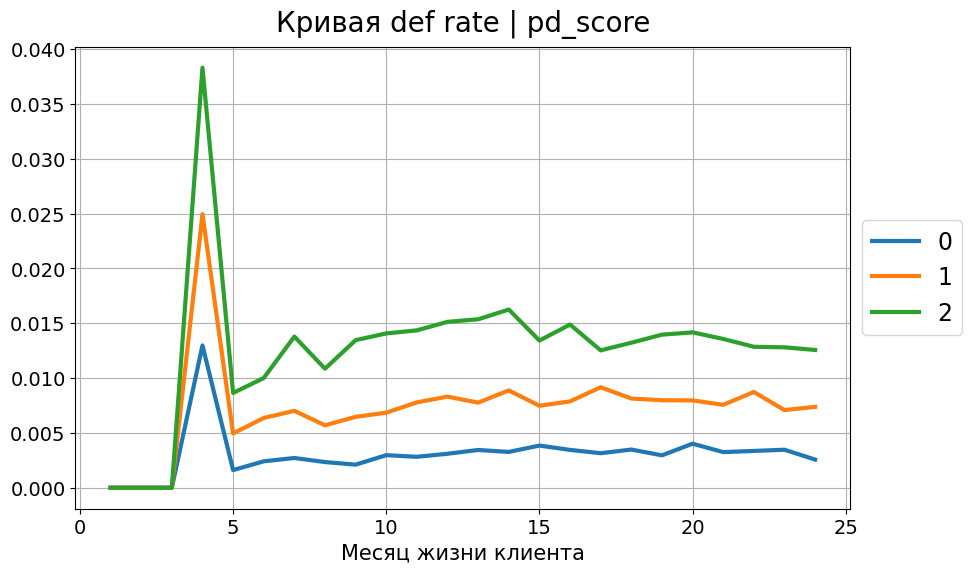

In [5]:
import matplotlib.pyplot as plt

plot_def_rate_by_bucket(df, "pd_bucket")
plt.title("Кривая def rate | pd_score", size=20, verticalalignment="bottom")
# код с семинара.
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize="17")
plt.xlabel("Месяц жизни клиента", size=15)
plt.tick_params(axis="both", which="major", labelsize=14)

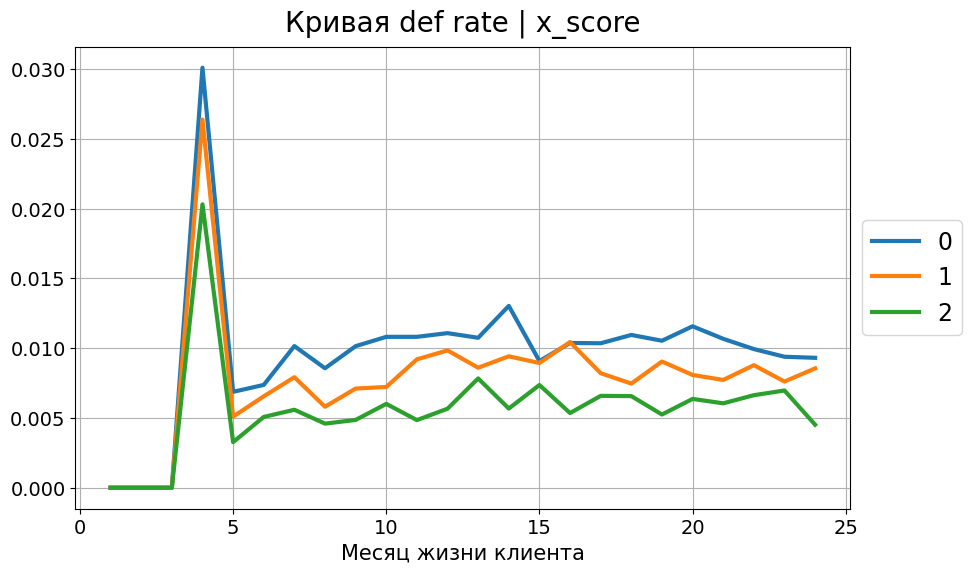

In [6]:
plot_def_rate_by_bucket(df, "x_bucket")
plt.title("Кривая def rate | x_score", size=20, verticalalignment="bottom")
# код с семинара.
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize="17")
plt.xlabel("Месяц жизни клиента", size=15)
plt.tick_params(axis="both", which="major", labelsize=14)

#### Вывод: здесь укажи выбранную тобой переменную и обоснуй свой выбор


Оба графики очень похожи, но если посмотреть на масштаб, то становится понятно, что лучше разделяет PD, так как расстояние между кривыми становится больше: это видно и по началу графика, так как кривые начинают раньше отличаться и перестают пересекаться визуально, так и по концу графика, так как там расстояния между кривыми банально больше, чем на втором графике, поэтому pd - наш выбор!

### Анализ поколений (0.5 баллов)

Отрисуй распределение данных во времени в разбивке по выбранной перменной

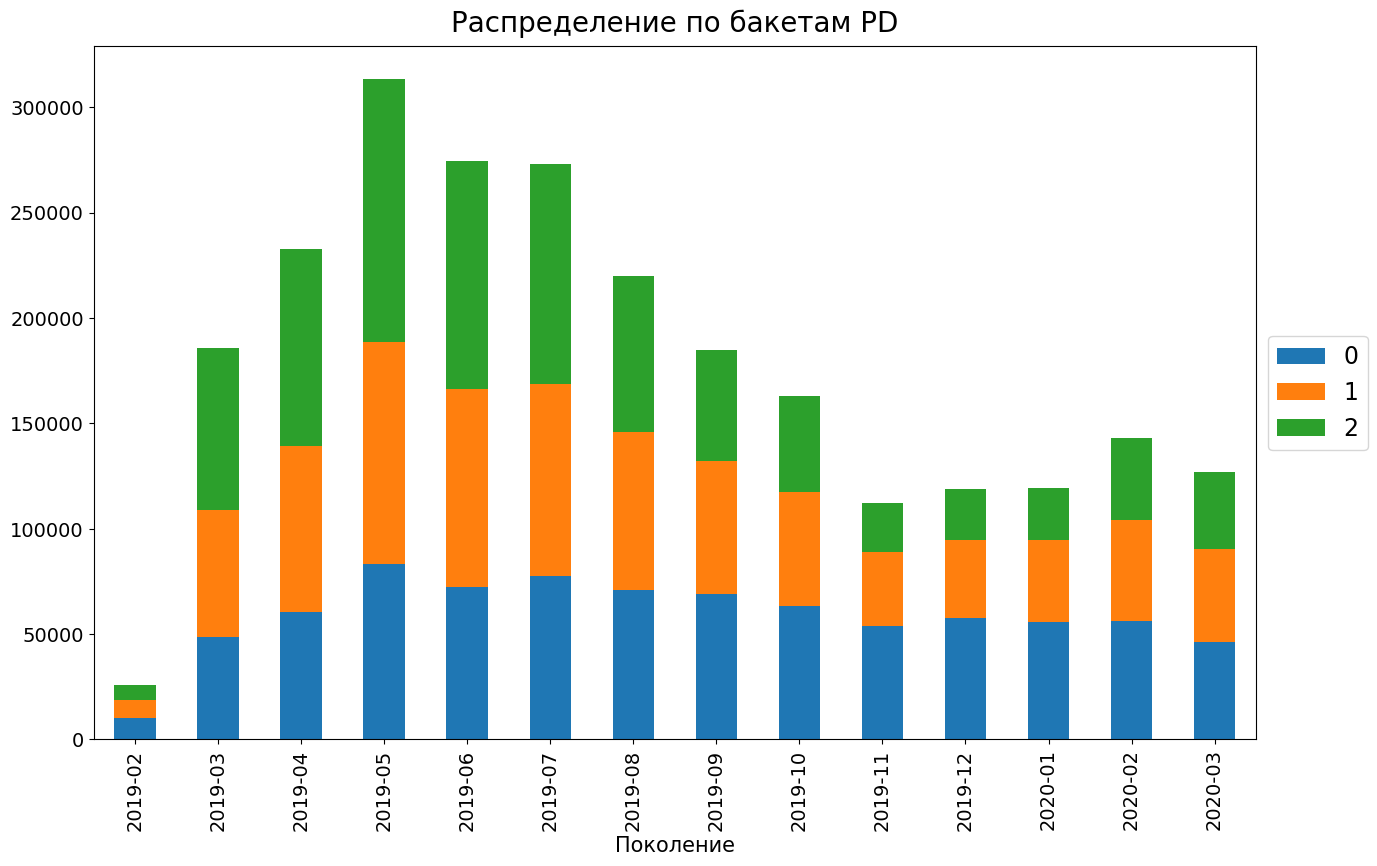

In [7]:
# код с семинара.
def plot_distribution(df, bucket):
    # Установить gen_month_dt как индекс
    df = df.set_index("gen_month_dt")

    # Теперь индекс — это DatetimeIndex, можно установить частоту
    df.index = df.index.to_period(freq="M")  # 'M' — ежемесячные данные

    return pd.pivot_table(
        df,
        index=[bucket],
        columns="gen_month_dt",  # делаем сводную таблицу и транспонируем ее
        values="user_id",
        aggfunc=np.count_nonzero,
        fill_value=0,
    ).T.plot(
        kind="bar", stacked=True, figsize=(15, 9)
    )  # Рисуем график распределения столбиками

plot_distribution(df, "pd_bucket")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize="17")
plt.title("Распределение по бакетам PD", size=20, verticalalignment="bottom")
plt.xlabel("Поколение", size=15)
plt.tick_params(axis="both", which="major", labelsize=14)

#### Вывод: сделай выводы по полученным графикам. Нужно ли исключать какие-то бакеты/поколения? Если да, то реализуй их исключение из выборки

Мы видим, что есть слишком малочисленное поколение ```2019-02```, которое нам стоит исключить, так как оно скорее всего будет для нас неинформативным. Бакеты исключать не нужно, они все примерно сбалансированы.

In [8]:
df = df[df['gen_month_dt'] != '2019-02-01']
df.head()

,user_id,statement_num,gen_month_dt,gen_quarter_dt,clo_flg,def_flg,dlq_flg,act_flg,prev_clo_flg,prev_def_flg,prev_dlq_flg,prev_act_flg,pd_bucket,x_bucket,pd,x_score
0,127336,19,2019-07-01,2019-07-01,0,0,0,1,0,0,0,1,1,2,0.021296,0.469410
1,35907,16,2019-04-01,2019-04-01,1,0,0,0,1,0,0,0,2,0,0.064742,0.157215
2,45228,21,2019-05-01,2019-04-01,0,0,0,1,0,0,0,1,0,2,0.018490,0.469583
3,39035,23,2019-07-01,2019-07-01,0,0,0,1,0,0,0,1,1,1,0.025882,0.210896
4,130780,19,2019-08-01,2019-07-01,1,0,0,0,1,0,0,0,1,1,0.024330,0.269492


### Кривые DEF Rate в разбивке по бакетам (0.5 баллов)

Реализуй функцию, которая отрисовывает винтажи DEF rate в разбивке по бакетам

In [9]:
def plot_def_rate_by_generation(df, bucket):
#     код функции
    (
        df.query(""" pd_bucket == @bucket""")
        .groupby(["gen_month_dt", "statement_num"])
        .agg({'def_flg': 'sum', 'prev_def_flg' : 'sum', 'prev_act_flg' : 'sum'})
        .rename(
            columns=({"def_flg": "def_cnt", "prev_def_flg": "prev_def_cnt", "prev_act_flg": "prev_act_cnt"})
        )
        .eval("def_rate = (def_cnt - prev_def_cnt) / prev_act_cnt", inplace=False)
        .unstack("gen_month_dt")["def_rate"]
        .plot(ax=None, figsize=(10, 6), grid=True, lw=3)
    )

    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize="17")
    plt.title(
        f"Кривая def rate, pd_bucket = {bucket}",
        size=20,
        verticalalignment="bottom",
    )
    plt.xlabel("Месяц жизни клиента", size=15)
    plt.tick_params(axis="both", which="major", labelsize=14)

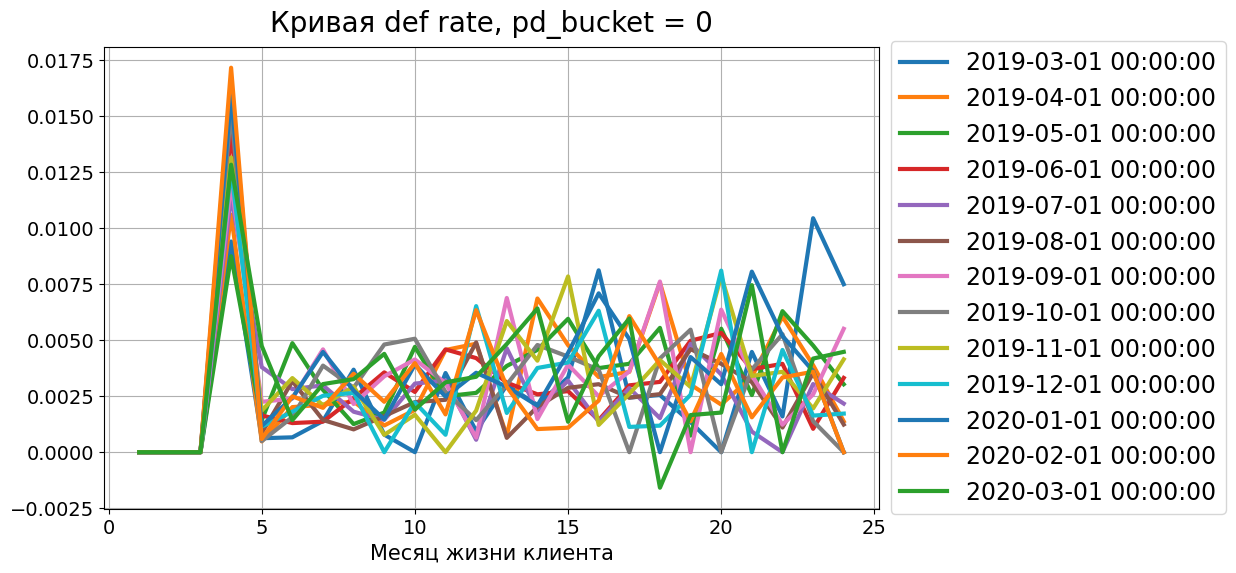

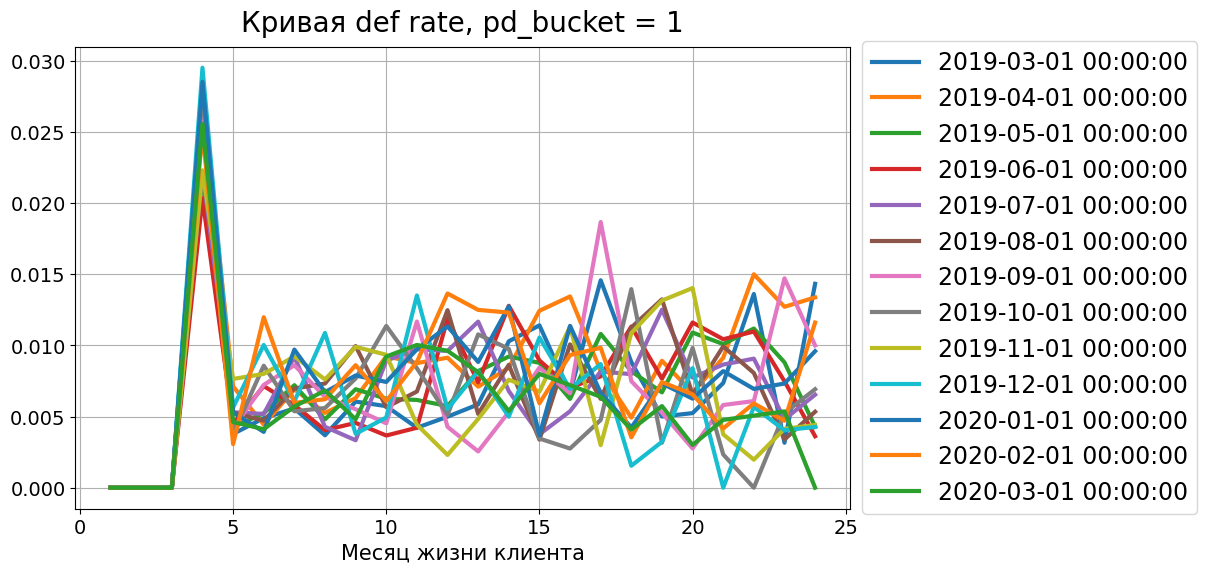

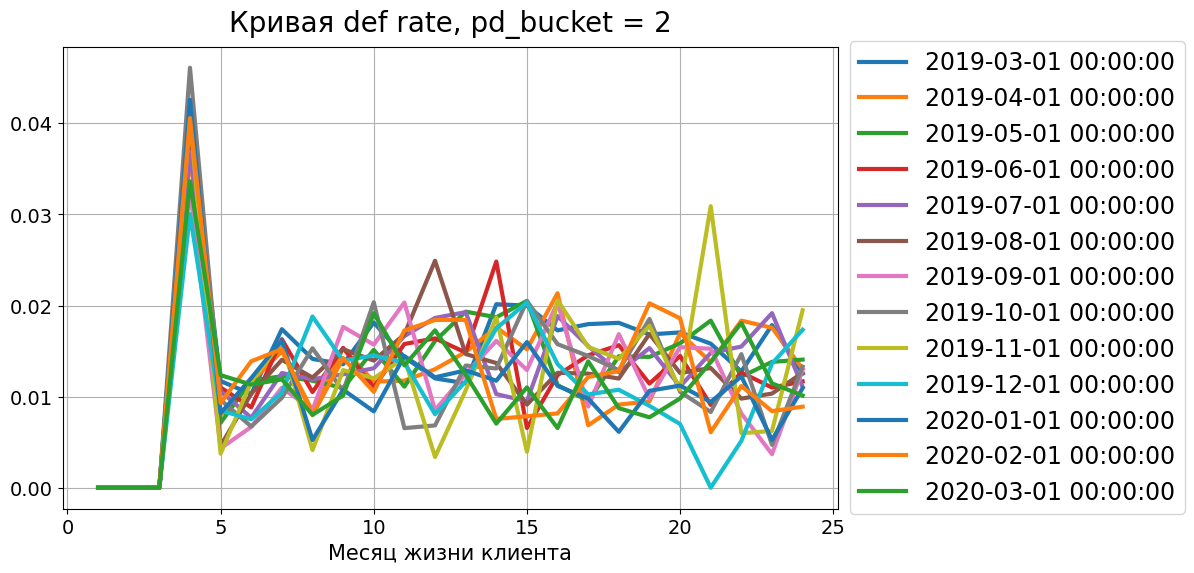

In [10]:
# код с семинара.
buckets = df["pd_bucket"].unique()
for i in sorted(buckets):
    plot_def_rate_by_generation(df, i)

#### Выводы: сделай выводы по полученным графикам


По графикам видно, что во всех бакетах вид кривых примерно одинаковый, только в нулевом бакете есть одно поколение, которое визуально выбивается под конец наблюдений, но все остальные поколения в этом бакеты и все поколения в остальных бакетах находятся в примерно одном пучке хаоса, что очень комфортно для анализа, так как легче найти общий вид кривой. Сначала кривая на нуле, потому что дефолты мы считаем только с 4 платежа, потом резко поднимаются на 4 платёж, а дальше убывает и стабилизируется, колеблясь примерно в одних и тех же значениях, но с дикой дисперсией.


### Особые точки (0.5 баллов) 
#### Есть ли в винтажах особые точки? Укажи их. Какова их природа? Нужно ли их исключать?



Как я и сказал в анализе выше, единственная необычная точка - это точка 4, но она обусловлена тем, что наш дефолт - это просрочка глубины 4, то есть вполне естественно, что до этой точки вероятность дефолта нулевая, потому что банально не прошло достаточно времени, а дальше уже люди начинают уходить в дефолты, и кривая сначала взрывается, а потом принимает своё стабильно-хаотичное состояние, поэтому нет никакого смысла их исключать, ведь это не какой-то выброс, а ожидаемое поведение.

### Макроэкономические воздействие (2 балла)

#### Есть ли в винтажах DEF rate макроэкономическое воздействие (нарисуй график иллюстрирующее это воздействие)? Если да, то предположи какое событие его вызвало и почему?
#### В случае наличия внешнего влияния 
#### 1) Разложи кривые на внешнее воздействие и созревание кривых
#### 2) Отрисуй график внешнего воздествия
#### 3) Отрисуй вычищенные винтажи DEF rate в разбивке по бакетам
#### 4) Посчитай среднее для этих бакетов и реализуй сглаживание

Не очень понятно, как я могу точно нарисовать иллюстрирующий это воздействие график, не разложив при этом нашу кривую в произведение двух, поэтому будем считать, что воздействие есть (на самом деле оно действительно есть, как минимум все колебания кривых явно вызваны внешними факторами, иначе все графики были бы идентичными). Кроме того, вот иллюстрирующий нарисованный график на примере 2-ого бакета :)
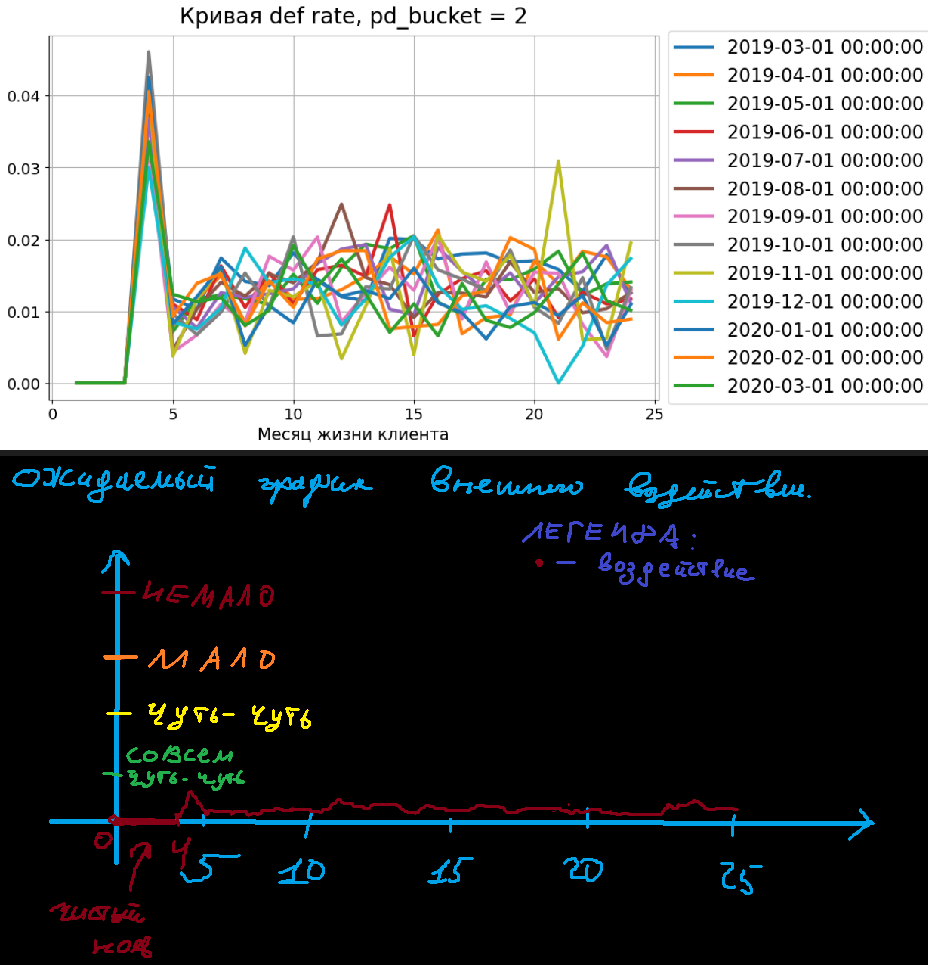

In [11]:
# код с семинара.
from scipy.optimize import minimize
def curve_build(data, feature, generation="generation_quart",
                statement_num="statement_num", group_label="1", stable_from=6):

    df_query = data.sort_values([generation, statement_num]).reset_index(drop=True)

    generation_min = df_query[generation].min()

    values = df_query[feature].to_numpy(dtype=float)
    st_nums = (df_query[statement_num].to_numpy(dtype=int) - 1)   # возраст a=0..A-1

    # календарный индекс t=0..T-1 для каждой строки
    dates = (
        df_query[generation].dt.year * 12 + df_query[generation].dt.month
        - (generation_min.year * 12 + generation_min.month)
        + df_query[statement_num].to_numpy(dtype=int) - 1
    ).to_numpy(dtype=int)

    A = int(st_nums.max() + 1)          # длина M(a)
    T = int(dates.max() + 1)            # длина E(t)
    tab_size = len(df_query)

    stable_mask = (np.arange(T) >= stable_from)  # t>=6

    def unpack_x(x):
        E_raw = x[:T]
        M_raw = x[T:T+A]

        # среднее только по "стабильному" окну
        if stable_mask.any():
            mean_E = E_raw[stable_mask].mean()
        else:
            mean_E = E_raw.mean()

        if mean_E == 0:
            mean_E = 1e-12

        # теперь mean(E[stable_mask]) == 1
        E = E_raw / mean_E

        # сохраняем инвариантность произведения E*M
        M = M_raw * mean_E
        return E, M

    def r_square(x):
        E, M = unpack_x(x)
        pred = E[dates] * M[st_nums]
        return np.sum((values - pred) ** 2)

    x0 = np.ones(T + A, dtype=float)

    res0 = minimize(
        r_square,
        x0,
        tol=1e-6,
        method="Powell",
        options={"disp": False, "maxiter": 1000},
    )

    # достаем уже нормированные E и M
    E_hat, M_hat = unpack_x(res0.x)

    external_data = pd.DataFrame({
        "month_dt": [generation_min + pd.DateOffset(months=i) for i in range(T)],
        group_label: E_hat
    })

    maturation_data = pd.DataFrame({
        "statement_num": np.arange(1, A + 1),
        group_label: M_hat
    })

    # fitted: D / E (если хотите "очистить" от макро)
    df_query = df_query.copy()
    df_query["month_dt"] = pd.to_datetime(df_query["month_dt"], errors="coerce")
    external_data["month_dt"] = pd.to_datetime(external_data["month_dt"], errors="coerce")

    df_fitted = df_query.merge(external_data, on="month_dt", how="left")
    df_fitted["fitted_feature"] = df_fitted[feature] / df_fitted[group_label]

    return {
        "res0": res0,
        "external_data": external_data,
        "maturation_data": maturation_data,
        "df_fitted": df_fitted,
    }

def decomposition(
    df,
    generation="generation_month",
    group="bucket",
    statement_num="statement_num",
    feature="feature",
    optimization_query="",
):
    """Винтажи исследуемой переменной по календарному времени

    **Аргументы**
    df : pandas.DataFrame
        таблица с данными
    generation : datetime
        название поля с поколениями
    group : str
        название поля с бакетами
    statement_num : int
        название поля с номером выписки
    feature: str
        название поля с исследуемой переменной
    optimization_query: str
        ограничение выборки для оптимизации
    **Результат**
    dictionary : dict
    """

    # Разбираемся со случаем пустых аргументов

    if optimization_query == "":
        df_query = pd.DataFrame(df)
    else:
        df_query = df.query(optimization_query)

    timedelta = df_query[statement_num].apply(lambda x: pd.DateOffset(months=x - 1))
    df_query["month_dt"] = df_query[generation] + timedelta

    # Формируем список бакетов

    df_query.sort_values(by=[group], inplace=True)
    groups = pd.Series(df_query[group].drop_duplicates())

    # Запускаем цикл по бакетам
    i = 0
    for g in groups:
        df_temp = df_query[df_query[group] == g]
        print(group + " = " + str(g))

        # Строим разложение для одного бакета
        res = curve_build(
            df_temp,
            feature=feature,
            generation=generation,
            statement_num=statement_num,
            group_label=str(g),
        )
        df_fitted_temp = pd.DataFrame(res["df_fitted"])
        df_fitted_temp[group] = g

        # Если первый шаг в цикле, то формируем датафреймы из результатов минимизации
        if i == 0:
            external_data = pd.DataFrame(res["external_data"])[["month_dt", str(g)]]
            maturation_data = pd.DataFrame(res["maturation_data"])[
                [statement_num, str(g)]
            ]
            df_fitted = pd.DataFrame(df_fitted_temp)
        # Если шаг не первый, то дописываем столбцы в результаты
        else:
            external_data = external_data.merge(
                right=res["external_data"], on=["month_dt"]
            )
            maturation_data = maturation_data.merge(
                right=res["maturation_data"], on=[statement_num]
            )
            df_fitted = pd.concat([df_fitted, df_fitted_temp])
        i += 1

    # print(res)

    res_multiple = {
        "external_data": external_data,
        "maturation_data": maturation_data,
        "fitted_data": df_fitted,
    }
    return res_multiple

In [12]:
def_rate = (
    df.groupby(["pd_bucket", "gen_month_dt", "statement_num"], as_index=False)
        .agg({'def_flg': 'sum', 'prev_def_flg' : 'sum', 'prev_act_flg' : 'sum'})
        .rename(
            columns=({"def_flg": "def_cnt", "prev_def_flg": "prev_def_cnt", "prev_act_flg": "prev_act_cnt"})
        )
        .eval("def_rate = (def_cnt - prev_def_cnt) / prev_act_cnt", inplace=False)
)

# код с семинара.
Nfeval = 0
res = decomposition(
    def_rate,
    generation="gen_month_dt",
    group="pd_bucket",
    statement_num="statement_num",
    feature="def_rate",
)
# Проверяем, что действительно нормировали внешку
stable_from = 6

E = res['external_data'][['0', '1', '2']].to_numpy()
t = np.arange(len(E))
mask = t >= stable_from

mean_stable = E[mask].mean()

print("Mean(E):", mean_stable)


C:\Users\temy2\AppData\Local\Temp\ipykernel_14212\4183113754.py:124: PerformanceWarning: Adding/subtracting object-dtype array to DatetimeArray not vectorized.
  df_query["month_dt"] = df_query[generation] + timedelta


pd_bucket = 0
pd_bucket = 1
pd_bucket = 2
Mean(E): 1.0


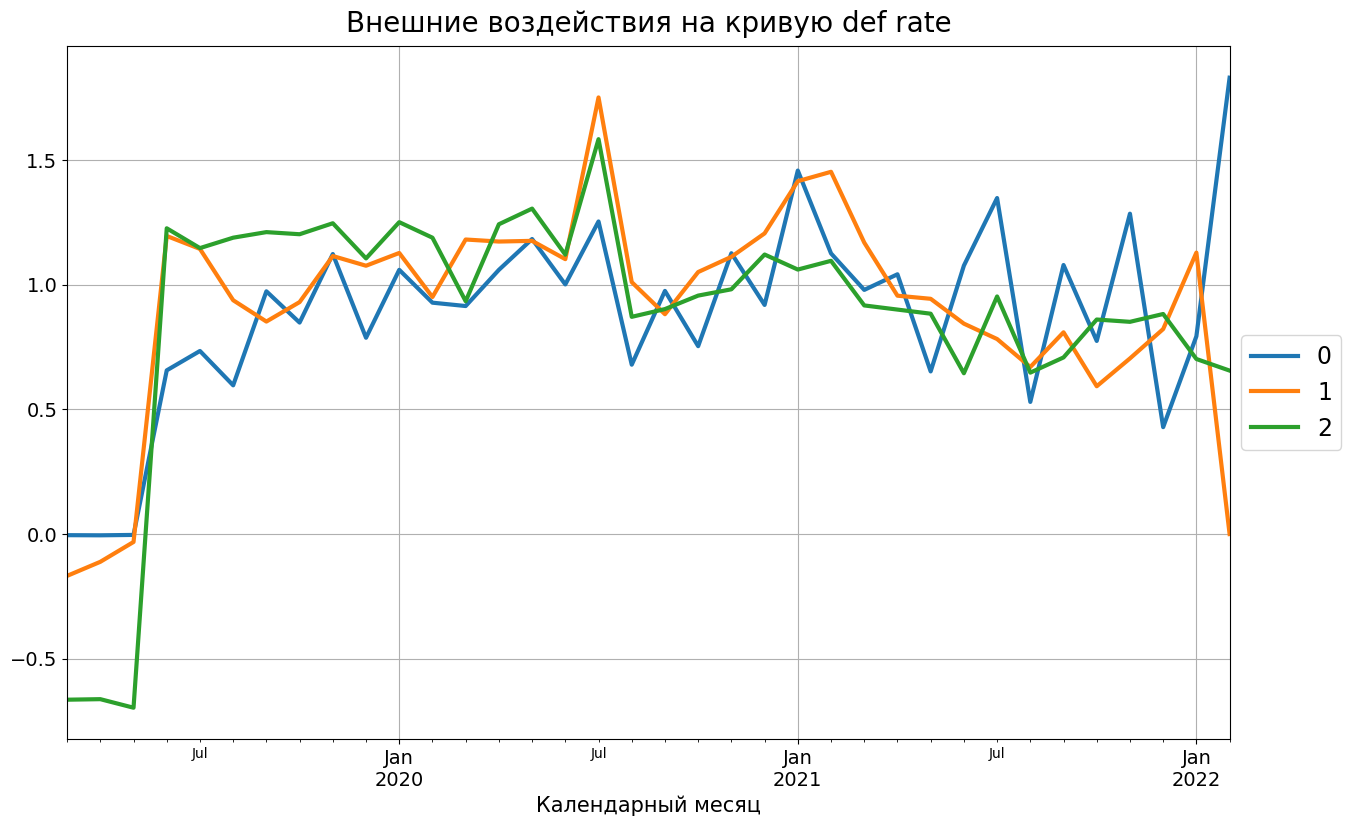

In [13]:
# код с семинара.
res["external_data"].set_index("month_dt").plot(
    ax=None, figsize=(15, 9), grid=True, lw=3
)

plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize="17")
plt.title(
    "Внешние воздействия на кривую def rate", size=20, verticalalignment="bottom"
)

plt.xlabel("Календарный месяц", size=15)
plt.tick_params(axis="both", which="major", labelsize=14)

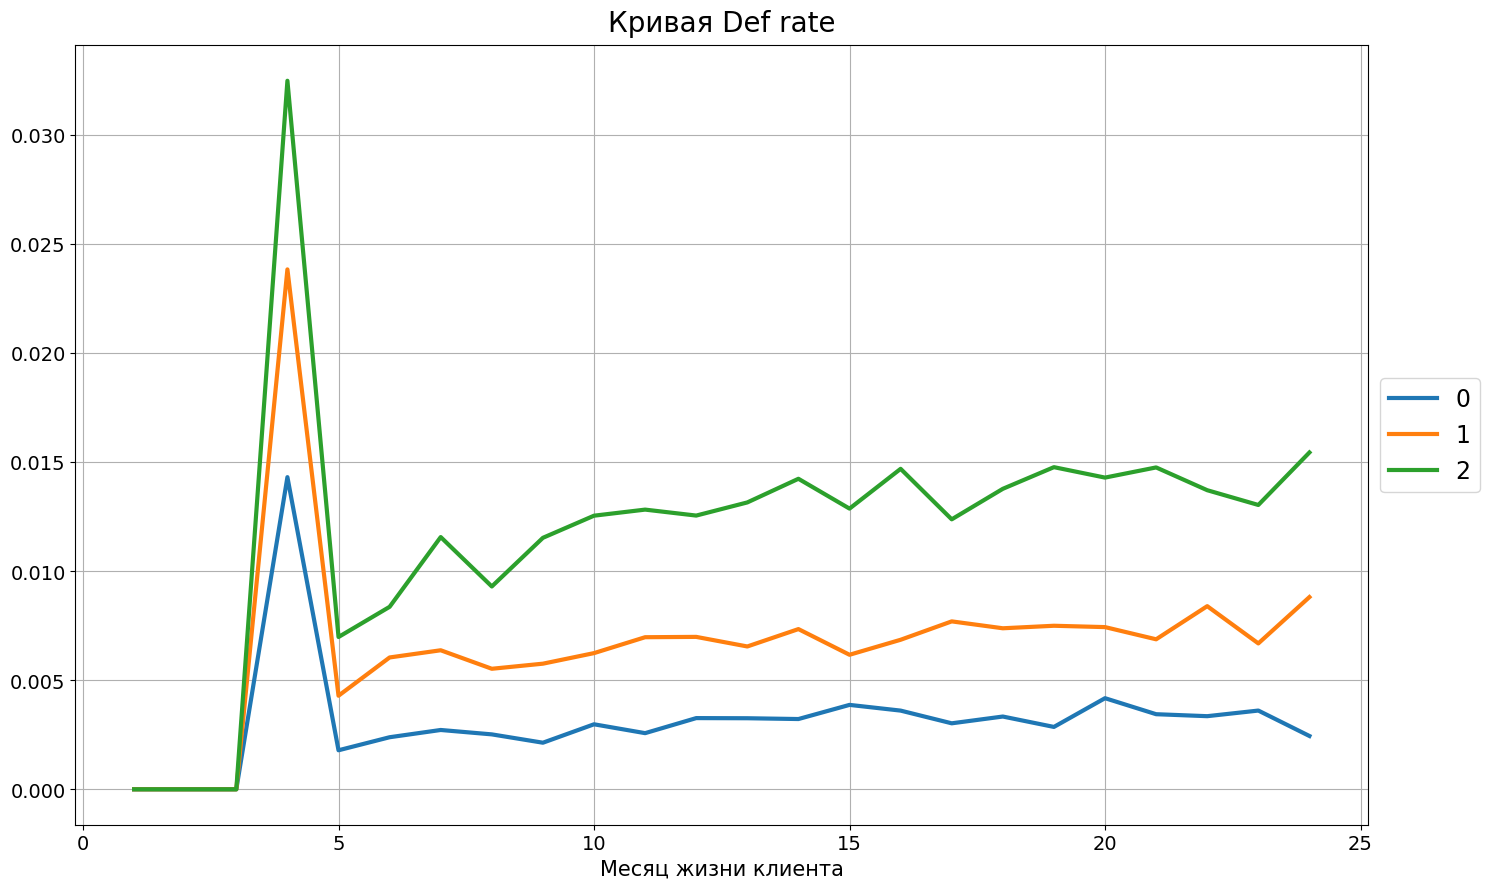

In [14]:
# код с семинара.
ax = (
    res["maturation_data"]
    .set_index("statement_num")
    .plot(figsize=(15, 9), grid=True, lw=3)
)

# Настройка легенды
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize="17")

# Добавление заголовка и меток осей
plt.title("Кривая Def rate", size=20, verticalalignment="bottom")
plt.xlabel("Месяц жизни клиента", size=15)

# Настройка подписей осей
plt.tick_params(axis="both", which="major", labelsize=14)

# Отображение графика
plt.tight_layout()
plt.show()

Среднее для бакетов и сглаживание выполнены в подпунктах ниже.

### Среднее по бакетам (0.5 баллов) 
Выбери один из способой нахождение средней кривой (возможные способы указаны в лекции). Обоснуй свой выбор.

Реализуй функцию построения среднего.

Сделаем средневзвешенную кривую, так как нам важно брать не просто среднее, а взвешивать его с учётом того, сколько у нас всего человек, так как иначе мы можем наблюдать какие-то взрывы значений, если, например, количество активных на прошлом платеже было маленьким, поэтому веса добавляют кривой стабильности.

In [15]:
# Реализация расчета среднего

#     код здесь

def_rate_mean = (
    res["fitted_data"]
    .groupby(["pd_bucket", "statement_num"])
    .agg({"def_cnt": 'sum', 'prev_def_cnt': 'sum', 'prev_act_cnt': 'sum'})
    .rename( 
        columns=({"def_cnt": "def_sum", 'prev_def_cnt' : "prev_def_sum", "prev_act_cnt": "prev_act_sum"})
        )
    .eval('Средневзвешенное = (def_sum - prev_def_sum) / prev_act_sum')
)

# Построй графики винтажей и среднего

def plot_def_rate_mean(bucket):
#     код функции
    (
        res["fitted_data"]
        .query(f"pd_bucket == {bucket}")
        .groupby(["gen_month_dt", "statement_num"])
        .agg({"fitted_feature": 'sum'})
        .unstack("gen_month_dt")["fitted_feature"]
        .plot(ax=None, figsize=(15, 9), grid=True, lw=3)
    ) 

    def_rate_mean.loc[bucket, "Средневзвешенное"].plot(
        figsize=(15, 9), grid=True, lw=3, color="Black", ls="dashed"
    )

    plt.legend(
        loc="center left", bbox_to_anchor=(1, 0.5), fontsize="17"
    )
    plt.title(
        f"Кривая Def rate, pd_bucket = {bucket}",
        size=20,
        verticalalignment="bottom",
    )
    plt.xlabel("Месяц жизни клиента", size=15)
    plt.tick_params(axis="both", which="major", labelsize=14)

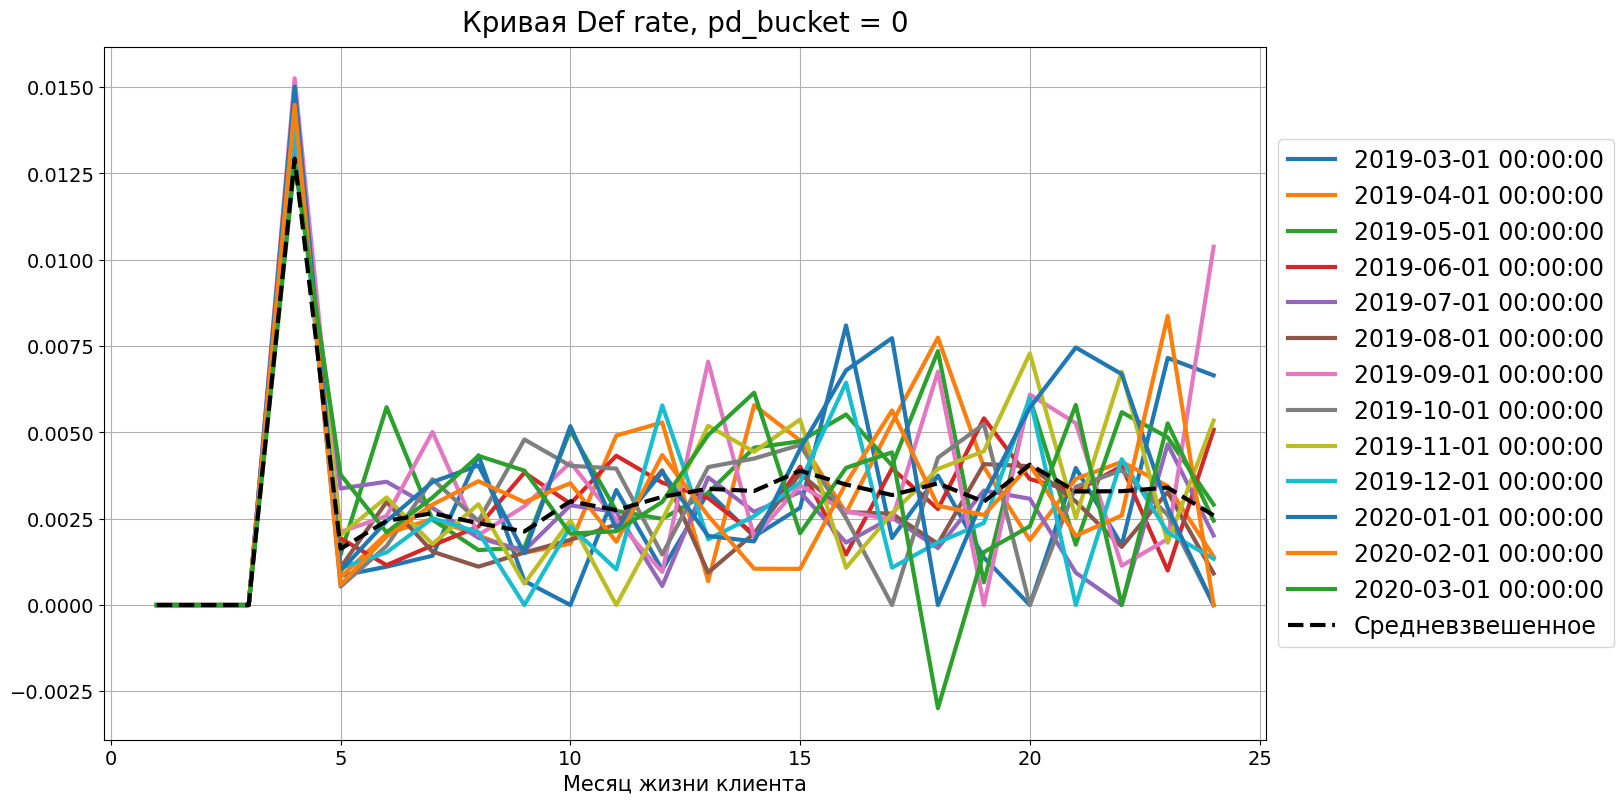

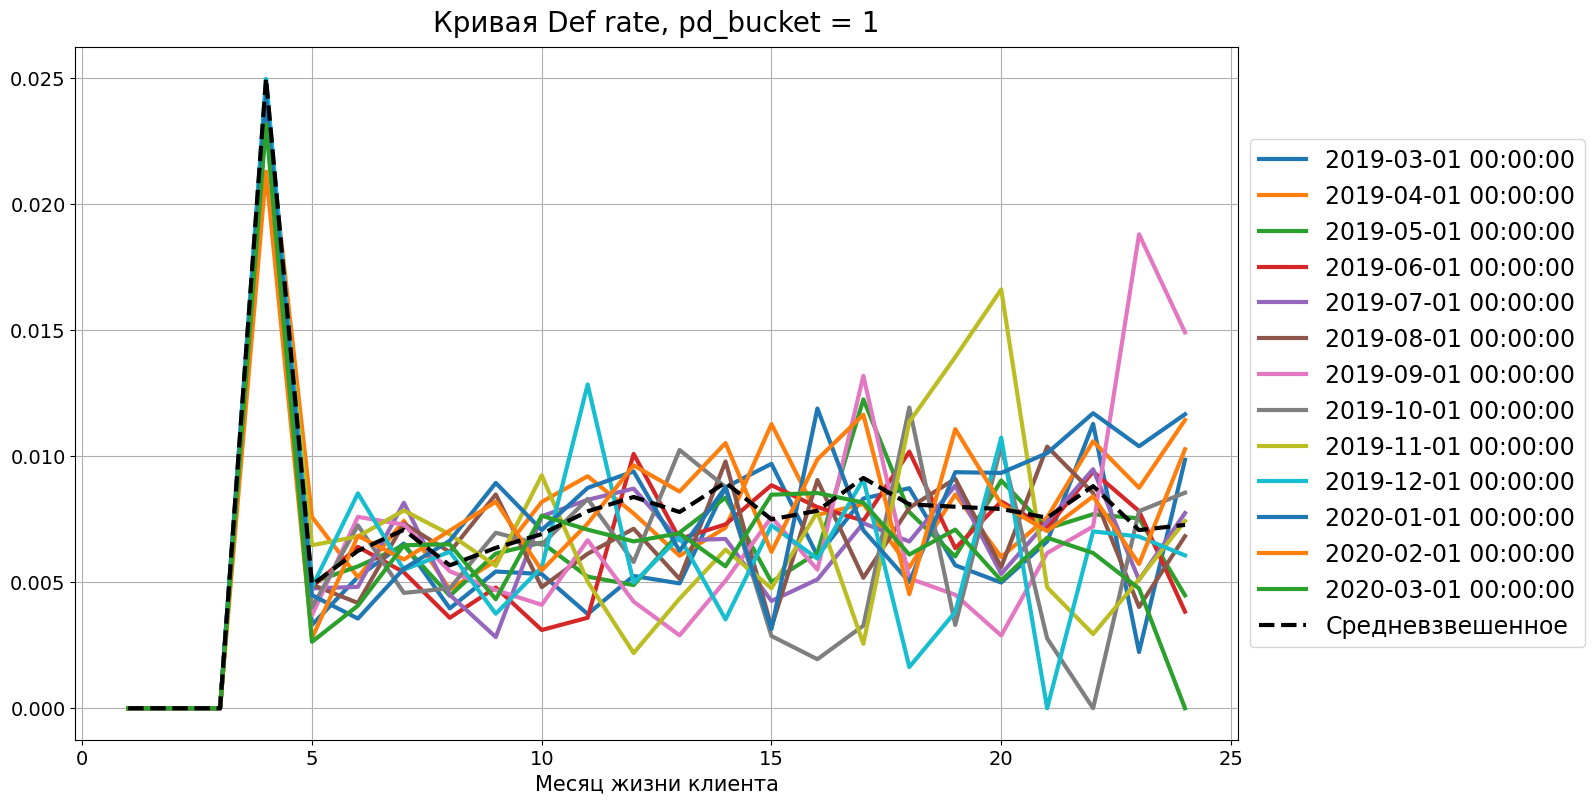

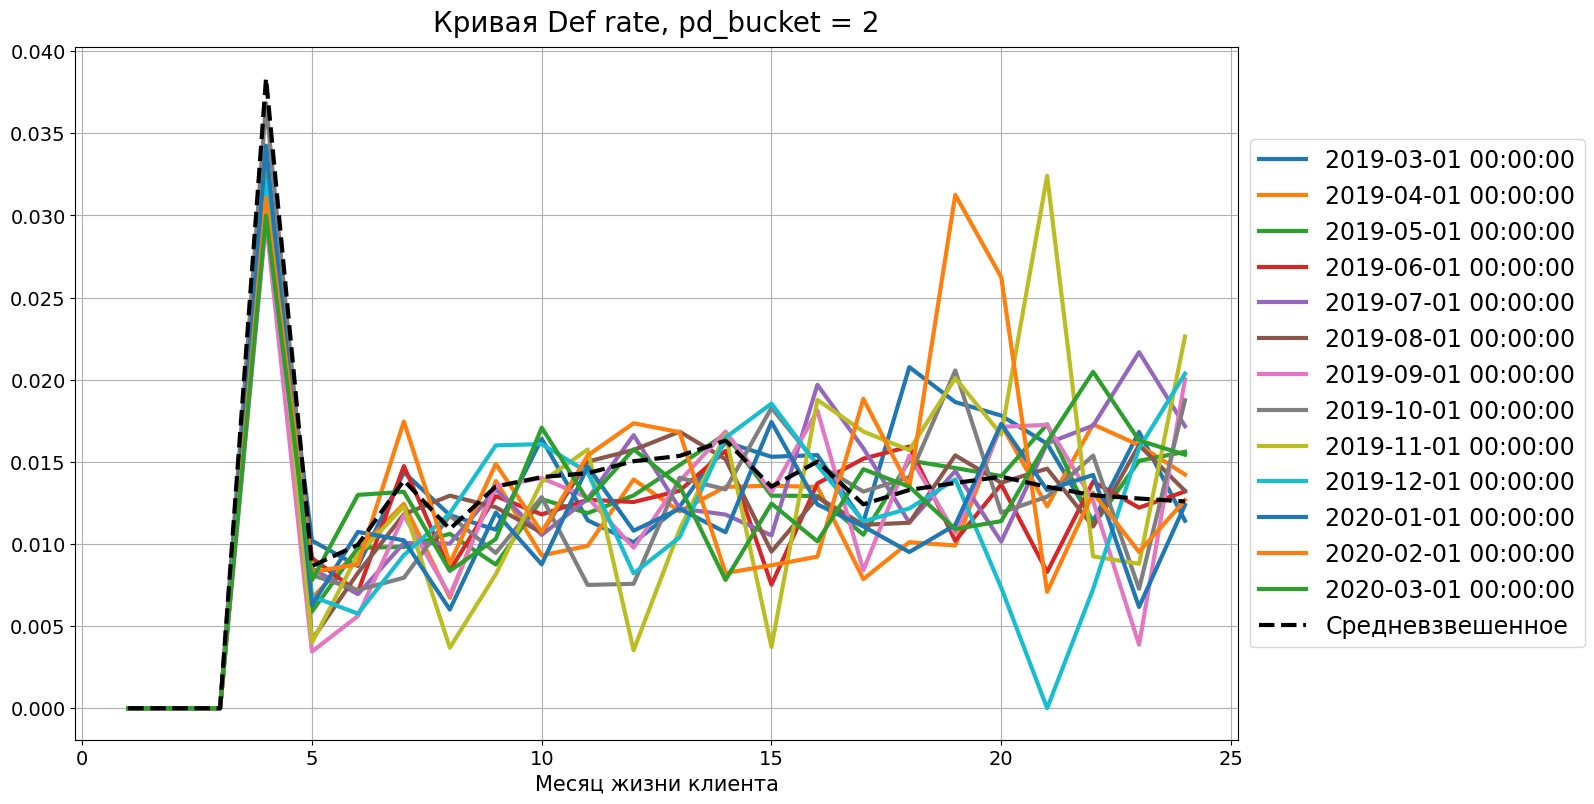

In [16]:
for i in sorted(buckets):
    plot_def_rate_mean(i)

### Сглаживание средних кривых (0.5 баллов) 

Рассмотри несколько функций для сглаживания кривой (можешь взять готовые из семинара, либо реализовать свои).

In [17]:
def linear_approximation(df, start=1, finish=24):
    df_res = pd.DataFrame(df)
    df_res["Линейная функция"] = df["Средневзвешенное"]  # Копируем средние значения
    linear_coeff = np.polyfit(
        np.arange(start, finish + 1), df.loc[start:finish, "Средневзвешенное"], 1
    )  # Коэффициенты уравнения прямой
    linear_coeff = np.poly1d(linear_coeff)  # Превращаем коэффициенты в функцию
    df_res.loc[start:finish, "Линейная функция"] = linear_coeff(
        np.arange(start, finish + 1)
    )  # Записываем приближение
    df_res.loc[finish + 1 :, "Линейная функция"] = linear_coeff(
        finish + 1
    )  # Продолжаем кривую константой
    return df_res


def polynom_approximation(df, start=1, finish=20, degree=1):
    df_res = pd.DataFrame(df)
    df_res["Полином"] = df["Средневзвешенное"]
    linear_coeff = np.polyfit(
        np.arange(start, finish + 1), df.loc[start:finish, "Средневзвешенное"], degree
    )  # Здесь произвольная степень
    linear_coeff = np.poly1d(linear_coeff)
    df_res.loc[start:finish, "Полином"] = linear_coeff(np.arange(start, finish + 1))
    df_res.loc[finish + 1 :, "Полином"] = linear_coeff(finish + 1)
    return df_res


def exponential_smoothing(df, start, finish, alpha):
    df_res = pd.DataFrame(df)
    result = [
        df_res.loc[i, "Средневзвешенное"] for i in np.arange(1, start + 1)
    ]  # Начальные значения копируем
    for n in range(start, len(df_res["Средневзвешенное"])):
        result.append(
            float(alpha * df_res.loc[n + 1, "Средневзвешенное"] + (1 - alpha) * result[n - 1])
        )  # Делаем сглаживание
    df_res["Скользящее среднее"] = result
    return df_res

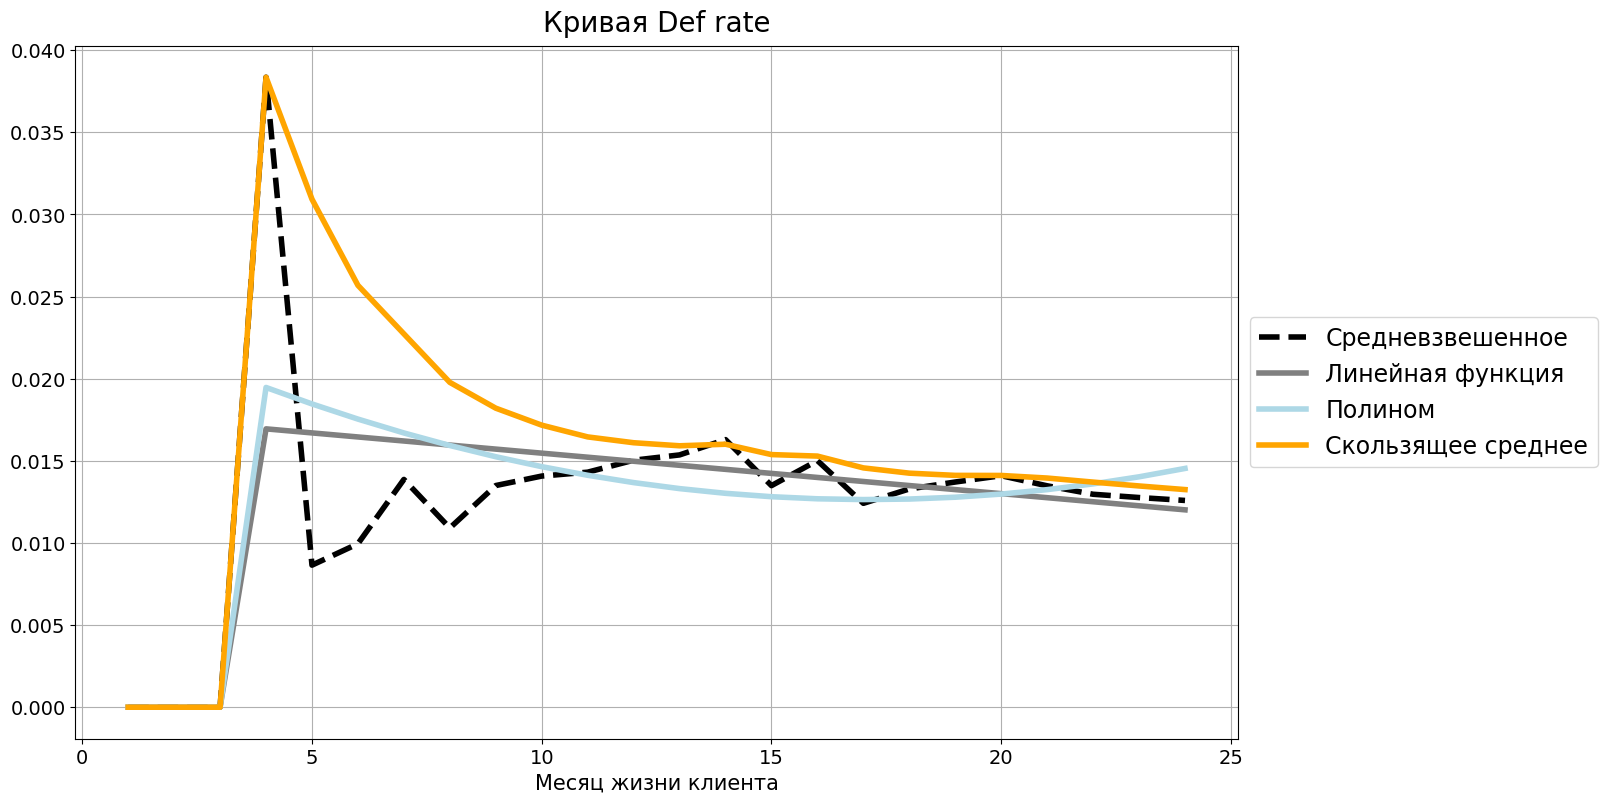

In [18]:
df_linear = (
    def_rate_mean.query("pd_bucket == 2").reset_index().set_index(["statement_num"])
)
df_linear = linear_approximation(df_linear, 4, 24)
df_polynom = polynom_approximation(df_linear, 4, 24, 2)
df_smooth = exponential_smoothing(df_polynom, 4, 24, 0.25)

# Строим получившиеся графики
plt.figure(figsize=(15, 9))
df_smooth["Средневзвешенное"].plot(grid=True, color="Black", linestyle="--", lw=4)
df_smooth["Линейная функция"].plot(grid=True, color="Gray", linestyle="-", lw=4)
df_smooth["Полином"].plot(grid=True, color="LightBlue", linestyle="-", lw=4)
df_smooth["Скользящее среднее"].plot(grid=True, color="Orange", linestyle="-", lw=4)

plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize="17")
plt.title("Кривая Def rate", size=20, verticalalignment="bottom")
plt.xlabel("Месяц жизни клиента", size=15)
plt.tick_params(axis="both", which="major", labelsize=14)

#### Вывод: укажи выбранную функцию и обоснуй свой выбор. Были ли точки, к которым не применил(-a) сглаживание? Почему?

Скользящее среднее слишком медленно падает, мы помним, что на наших данных после пика на 4 месяце мы столь же быстро падаем и стабилизируемся, чего не происходит при таком сглаживании, поэтому оно нам не подходит. Линейное сглаживание слишком простое и не улавливает важных скачков, поэтому оно нам тоже не подходит. Выбор остаётся из двух: либо взять полином либо оставить средневзвешенное, но средневзвешенное слишком хаотично, поэтому лучше всего наши данные приближает полином. Однако здесь важное уточнение, что полиномом мы сглаживаем, начиная с 5 точки, так как иначе полином плохо улавливает пик на 4, который естественен и который мы ожидаем, а если этого не сделать, то полином хорошо улавливает ситуацию после 4 месяца, но плохо до него, поэтому важно сглаживание применять не ко всем точкам.

### Отрисуй сглаженные кривые по всем трем бакетам PD

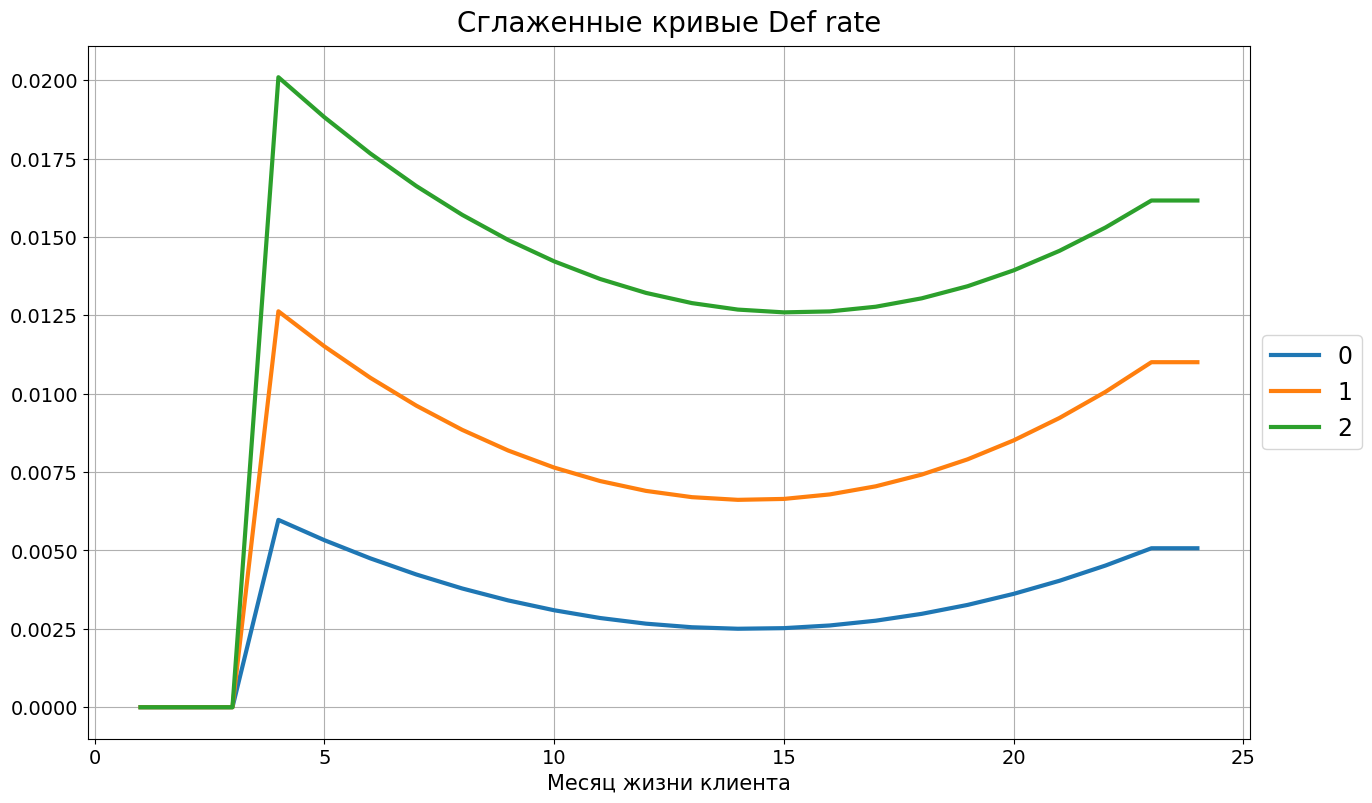

In [19]:
# код здесь
df_smooth_result = pd.DataFrame()
for x in sorted(buckets):
    df_temp = (
        def_rate_mean.query(f"pd_bucket == {str(x)}")
        .reset_index()
        .set_index(["statement_num"])
    )
    df_smooth_result[str(x)] = polynom_approximation(df_temp, 4, 22, 2)["Полином"]

df_smooth_result.plot(figsize=(15, 9), grid=True, lw=3)
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize="17")
plt.title("Сглаженные кривые Def rate", size=20, verticalalignment="bottom")
plt.xlabel("Месяц жизни клиента", size=15)
plt.tick_params(axis="both", which="major", labelsize=14)

# Внедрение в NPV-модель

## Добавь в NPV-модель метод с расчетом DEF rate по твоей кривой

На лекции нам говорили о том, что кривые для общей модели можно подбирать как что-то среднее между кривыми, бакеты которых в каком-то смысле зажимают нашу подвыборку (то есть допустим, мы смотрим на бакет с pd = 5, а кривые подсчитаны для pd = 2, 7, 9, тогда нас интересует кривая между первыми двумя), но проблема в том, что в нашей NPV модели не моделируются разные бакеты и в ней нет скоринговых данных, чтобы мы сами относили кого-то к какому-то бакету, поэтому мы либо передаём, по какому конкретно бакету считаем, либо усредняем наши кривые, так как адаптировать их не можем. Эту логику перенесём в саму модель, а здесь просто демонстрация итогового распределения.

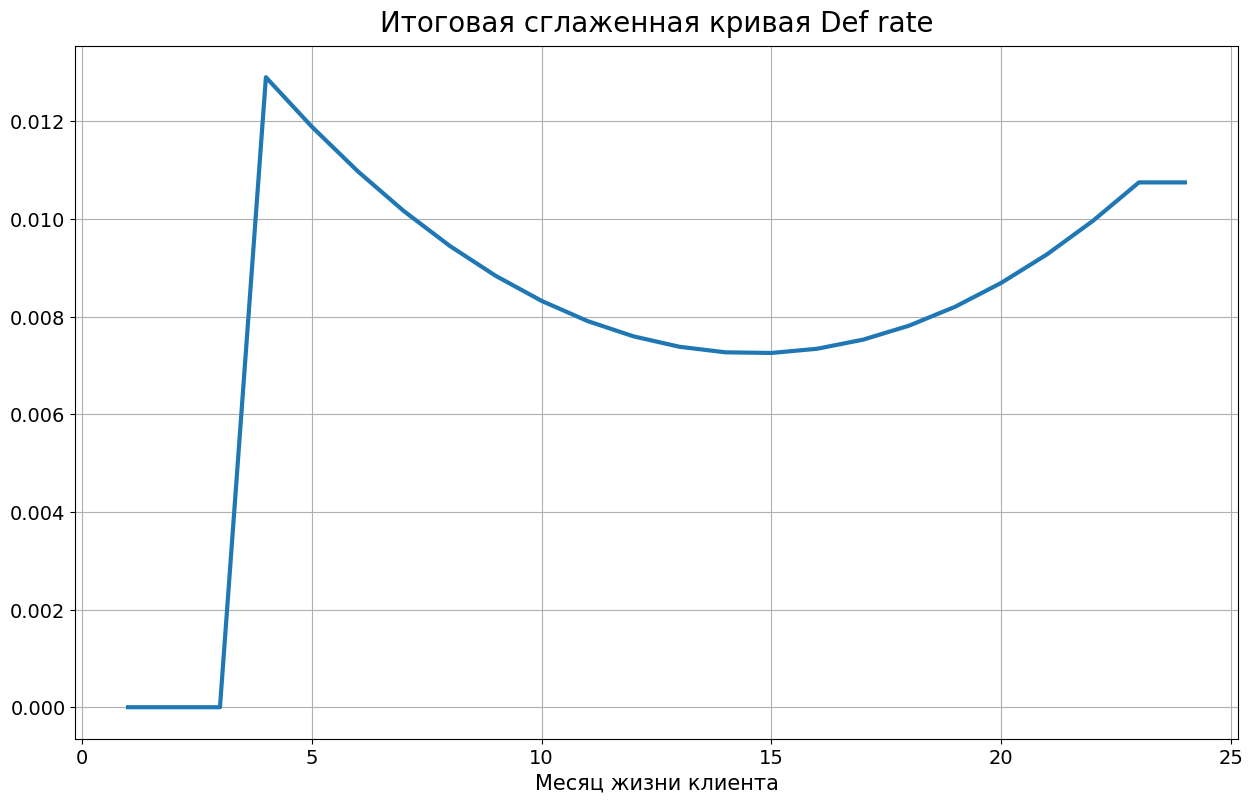

In [20]:
def_curve = df_smooth_result.mean(axis=1)
def_curve.plot(figsize=(15, 9), grid=True, lw=3)
plt.title("Итоговая сглаженная кривая Def rate", size=20, verticalalignment="bottom")
plt.xlabel("Месяц жизни клиента", size=15)
plt.tick_params(axis="both", which="major", labelsize=14)

In [21]:
# Код NPV-модели с прошлого семинара

import numpy as np

class NPVModel:

    avg_missed_payments = 1.5
    recovery = 0.50
    dlq_penalty_amount = 500
    oper_costs = 100
    collection_costs = 600
    tax_rate = 0.20
    discounting_rate = 0.30
    eq_req = 0.125
    cost_of_funds = 0.16
    dlq_ratio = np.ones(101)*0.20
    dlq_ratio[0] = 0
    shift = 4
    clo_rate = 1 / (np.arange(shift, shift + 101) ** 2)
    acquisition_cost = 1000

    def __init__(self):
        pass

    def model_balance_calculations(self, amount, rate, term):
        '''
        Расчет модельных баланса, выплаченных процентов, регулярного платежа
        :param amount: Сумма кредита
        :param rate: Ставка
        :param term: Срок
        :return:
        balance : np.array(101) : остаток тела долга по кредиту на каждый месяц
        interest : np.array(101) : выплата по процентам каждый месяц
        regular_payment : float : размер регулярного платежа
        '''

        regular_payment = round(amount * (rate / 12) *\
                                (1 + (rate / 12)) / (1 - ((1 + rate / 12) ** (-term))))
        # График баланса и процентов
        balance = np.zeros(101)
        interest = np.zeros(101)
        balance[0] = amount

        for i in range(1, term + 1):
            int_payment = balance[i - 1] * rate / 12
            debt_payment = regular_payment - int_payment
            balance[i] = max(0, round(balance[i - 1] - debt_payment))
            interest[i] = int_payment
        return balance, interest, regular_payment

    def distribution_calc(self, portfolio_distribution, pd=None, pa=None):
        '''
        Расчет распределения по статусам
        :param portfolio_distribution: график распределения по статусам
        :return:
        cur_dist : np.array(101) : доля клиентов в статусе CUR на каждый месяц
        dlq_dist : np.array(101) : доля клиентов в статусе DLQ на каждый месяц
        act_dist : np.array(101) : доля клиентов в статусе ACT на каждый месяц
        def_dist : np.array(101) : доля клиентов в статусе DEF на каждый месяц
        clo_dist : np.array(101) : доля клиентов в статусе CLO на каждый месяц
        '''
        
        cur_dist = portfolio_distribution['CUR']
        dlq_dist = portfolio_distribution['DLQ']
        act_dist = cur_dist + dlq_dist
        def_dist = portfolio_distribution['DEF'] 
        clo_dist = portfolio_distribution['CLO']


        return cur_dist, dlq_dist, act_dist, def_dist, clo_dist

    def cur_balance_calc(self, model_balance, cur_dist):
        '''
        Расчет модельного баланса в статусе CUR
        :param model_balance: плановый график баланса
        :param cur_dist: доля клиентов в статусе CUR на каждый месяц
        :return:
        principal_balance_cur : np.array(101) : principal balance в статусе CUR
        gross_balance_cur : np.array(101) : gross balance в статусе CUR
        '''
        principal_balance_cur = model_balance*cur_dist
        gross_balance_cur = model_balance*cur_dist
        return principal_balance_cur, gross_balance_cur

    def dlq_balance_calc(self, model_balance, regular_payment, dlq_dist):
        '''
        Расчет модельного баланса в статусе DLQ
        :param model_balance: плановый график баланса
        :param regular_payment: размер регулярного платежа
        :param dlq_dist: доля клиентов в статусе DLQ на каждый месяц
        :return:
        principal_balance_dlq : np.array(101) : principal balance в статусе DLQ
        gross_balance_dlq : np.array(101) : gross balance в статусе DLQ
        '''
        principal_balance_dlq = np.append(model_balance[1:], model_balance[-1])*dlq_dist
        gross_balance_dlq = (model_balance + regular_payment*self.avg_missed_payments)*dlq_dist
        return principal_balance_dlq, gross_balance_dlq

    def act_balance_calc(self, principal_balance_cur, principal_balance_dlq, gross_balance_cur, gross_balance_dlq):
        '''
        Расчет модельного баланса в статусе ACT
        :param principal_balance_cur: principal balance в статусе CUR
        :param principal_balance_dlq: principal balance в статусе DLQ
        :param gross_balance_cur: principal balance в статусе CUR
        :param gross_balance_dlq: principal balance в статусе DLQ
        :param dlq_dist: доля клиентов в статусе DLQ на каждый месяц
        :return:
        principal_balance_act : np.array(101) : principal balance в статусе ACT
        gross_balance_act : np.array(101) : gross balance в статусе ACT
        '''
        principal_balance_act = principal_balance_cur + principal_balance_dlq
        gross_balance_act = gross_balance_cur + gross_balance_dlq
        return principal_balance_act, gross_balance_act

    def def_balance_calc(self, model_balance, regular_payment, def_dist):
        '''
        Расчет модельного баланса в статусе DEF
        :param model_balance: плановый график баланса
        :param regular_payment: размер регулярного платежа
        :param def_dist: доля клиентов в статусе DEF на каждый месяц
        :return:
        principal_balance_def : np.array(101) : principal balance в статусе DEF
        gross_balance_def : np.array(101) : gross balance в статусе DEF
        '''
        principal_balance_def = np.zeros(101)
        gross_balance_def = np.zeros(101)

        def_dist_change = def_dist[4:] - def_dist[3:-1]
        principal_balance_def[4:] = np.cumsum(model_balance[:-4] * def_dist_change)
        gross_balance_def[4:] = np.cumsum((model_balance[4:] + 4 * regular_payment) * def_dist_change)

        return principal_balance_def, gross_balance_def

    def profit_calc(self, principal_balance_act, principal_balance_def, term, rate, dlq_dist):
        '''

        :param principal_balance_act: principal balance в статусе ACT
        :param principal_balance_def: principal balance в статусе DEF
        :param term: срок кредита
        :param rate: тавка по кредиту
        :param dlq_dist: доля клиентов в статусе DLQ на каждый месяц
        :return:
        profit : np.array(101) : доход на каждый месяц
        '''
        interest_profit = principal_balance_act*rate/12
        penatly_profit = dlq_dist*self.dlq_penalty_amount

        new_def_balance = np.append(principal_balance_def[1:], 0) - principal_balance_def
        recovery_profit = new_def_balance*self.recovery

        profit = interest_profit + recovery_profit + penatly_profit
        profit[term+1:] = 0

        return profit

    def loss_calc(self, gross_balance_act, principal_balance_def, term, act_dist, dlq_dist, def_dist):
        '''

        :param gross_balance_act: gross balance в статусе ACT
        :param principal_balance_def: principal balance в статусе DEF
        :param term: срок кредита
        :param act_dist: доля клиентов в статусе ACT на каждый месяц
        :param dlq_dist: доля клиентов в статусе DLQ на каждый месяц
        :param def_dist: доля клиентов в статусе DEF на каждый месяц
        :return:
        loss : np.array(101) : лосс на каждый месяц
        '''
        oper_loss = np.append(act_dist[1:], 0)*self.oper_costs
        loan_loss =  principal_balance_def - np.append(0, principal_balance_def[:-1])
        collection_loss = (np.append(dlq_dist[1:], 0) + np.append(def_dist[1:], 0))*self.collection_costs

        prev_gross_balance_act = np.append(gross_balance_act[0], gross_balance_act[1:])
        cost_of_funds_loss = prev_gross_balance_act*(1 - self.eq_req)*self.cost_of_funds/12

        loss = loan_loss + cost_of_funds_loss + oper_loss + collection_loss
        loss[term+1:] = 0

        return loss, loan_loss, cost_of_funds_loss, oper_loss, collection_loss

    def assets_liabilities_calc(self, gross_balance_act):
        '''

        :param gross_balance_act: gross balance в статусе ACT
        :return:
        assets : np.array(101) : активы в проекте
        eq_req_curve : np.array(101) : активы, обеспеченные капиталом
        fund_req_curve : np.array(101) : активы, обеспеченные фондами
        '''

        # assets
        assets = gross_balance_act

        #liabilities
        eq_req_curve = assets*self.eq_req
        fund_req_curve = assets*(1 - self.eq_req)

        return assets, eq_req_curve, fund_req_curve

    def niat_calc(self, profit, loss):
        '''
        Расчет NIAT
        :param profit: суммарный доход на каждый месяц
        :param loss: суммарный лосс на каждый месяц
        :return:
        nibt : np.array(101) : прибыль до налогообложения
        niat : np.array(101) : прибыль после налогообложения
        tax : np.array(101) : налог в каждом месяце
        '''

        nibt = profit - loss
        tax = nibt*self.tax_rate
        niat = nibt - tax

        return nibt, niat, tax

    def cashflow_calc(self, principal_balance_act, principal_balance_def, amount, profit,
                      cost_of_funds_loss, oper_costs, collection_costs, tax, niat, eq_req_curve, fund_req_curve):
        '''
        Расчет денежных потоков
        :param principal_balance_act: principal balance в статусе DEF
        :param principal_balance_def: principal balance в статусе DEF
        :param amount: срок кредита
        :param profit: доход на каждый месяц
        :param cost_of_funds_loss: лоссы на фондирование
        :param oper_costs: операционные расходы
        :param collection_costs: расходы на коллекшн
        :param tax: налог в каждом месяце
        :param niat: доход после налогообложения
        :param eq_req_curve: активы, обеспеченные капиталом
        :param fund_req_curve: активы, обеспеченные фондами
        :return:
        cf_to_client : np.array(101) : денежный поток к клиенту
        cf_to_shareholders : np.array(101) : денежный поток к акционерам
        cf_to_debtholders : np.array(101) : денежный поток к фондам
        cf_to_cost_and_tax : np.array(101) : денежный поток на косты и налоги
        '''
        # client
        delta_principal_balance_act = (np.append(0, principal_balance_act[:100]) - principal_balance_act)
        delta_principal_balance_def = (np.append(0, principal_balance_def[:100]) - principal_balance_def)
        repayments = delta_principal_balance_act - delta_principal_balance_def + profit
        cf_to_client = np.append(amount, -repayments[1:])

        # debtoholder
        fund_req_ch = fund_req_curve - np.append(fund_req_curve[0], fund_req_curve[:-1])
        fund_req_change = np.append(fund_req_curve[0], fund_req_ch[1:])
        cf_to_debtholders = cost_of_funds_loss - fund_req_change

        # shareholders
        eq_req_ch = eq_req_curve - np.append(eq_req_curve[0], eq_req_curve[:-1])
        cf_to_shareholders = niat - np.append(eq_req_curve[0], eq_req_ch[1:])

        # cost and tax
        cf_to_cost_and_tax = oper_costs + collection_costs + tax

        return cf_to_client, cf_to_shareholders, cf_to_debtholders, cf_to_cost_and_tax
        
    def npv_calc(self, amount, rate, term, def_curve, pd=None):
        '''
        Расчет NPV с внутренним вычислением portfolio_distribution
        :param amount: сумма кредита
        :param rate: ставка по кредиту
        :param term: срок кредита
        :param def_rate: доля дефолтных клиентов к концу срока
        :param clo_rate: доля закрытых клиентов к концу срока
        :param pd: вероятность дефолта к 12-ому месяцу
        :param pa: вероятность полного досрочного погашения к 6-ому месяцу
        :return: npv: чистая приведенная стоимость кредита
        '''

        # Считаем балансы
        model_balance, interest, regular_payment = self.model_balance_calculations(amount, rate, term)
        
        # Рассчитываем распределение по статусам
        cur_dist = np.zeros(101)
        dlq_dist = np.zeros(101)
        def_dist = np.zeros(101)
        clo_dist = np.zeros(101)
        act_dist = np.zeros(101)
        
        # В начале все клиенты в статусе CUR
        act_dist[0] = 1
        cur_dist[0] = 1
        
        self.def_rate = self.def_rate_calc(def_curve, pd)
        
        for i in range(1, term + 1):
            clo_dist[i] = clo_dist[i - 1] + self.clo_rate[i] * act_dist[i - 1]
            def_dist[i] = def_dist[i - 1] + self.def_rate[i] * act_dist[i - 1]
            act_dist[i] = max(0, 1 - clo_dist[i] - def_dist[i])
            dlq_dist[i] = self.dlq_ratio[i] * act_dist[i]
            cur_dist[i] = act_dist[i] - dlq_dist[i]
            

        portfolio_distribution = {
            'CUR': cur_dist,
            'DLQ': dlq_dist,
            'DEF': def_dist,
            'CLO': clo_dist
        }

        # Считаем распределение
        cur_dist, dlq_dist, act_dist, def_dist, clo_dist = self.distribution_calc(portfolio_distribution)

        # Считаем балансы
        principal_balance_cur, gross_balance_cur = self.cur_balance_calc(model_balance, cur_dist)
        principal_balance_dlq, gross_balance_dlq = self.dlq_balance_calc(model_balance, regular_payment, dlq_dist)
        principal_balance_act, gross_balance_act = self.act_balance_calc(principal_balance_cur, principal_balance_dlq, gross_balance_cur, gross_balance_dlq)
        principal_balance_def, gross_balance_def = self.def_balance_calc(model_balance, regular_payment, def_dist)

        # Считаем профиты
        profit = self.profit_calc(principal_balance_act, principal_balance_def, term, rate, dlq_dist)
        loss, loan_loss, cost_of_funds_loss, oper_loss, collection_loss = self.loss_calc(gross_balance_act, principal_balance_def,
                                                                                        term, act_dist, dlq_dist, def_dist)
        nibt, niat, tax = self.niat_calc(profit, loss)

        # Считаем активы и денежные потоки
        assets, eq_req_curve, fund_req_curve = self.assets_liabilities_calc(gross_balance_act)
        cf_to_client, cf_to_shareholders, cf_to_debtholders, cf_to_cost_and_tax =\
            self.cashflow_calc(principal_balance_act, principal_balance_def, amount, profit, cost_of_funds_loss, oper_loss, collection_loss,
                            tax, niat, eq_req_curve, fund_req_curve)

        # Считаем NPV
        disc_curve = np.array([1 / ((1 + self.discounting_rate) ** (i / 12.)) for i in range(101)])
        pv = np.round(np.sum(disc_curve * cf_to_shareholders)).astype(int)
        npv = pv - self.acquisition_cost

        return npv
    
    
    def def_rate_calc(self, df_smooth_result, pd=None):
        # Реализуй тут метод для расчета def_rate
        # Метод должен возвращать def_rate
        if pd == None: 
            def_rate_24_months = df_smooth_result.mean(axis=1) # тут чисто усредняем.
        else: 
            def_rate_24_months = df_smooth_result[str(pd)] # тут по заданному бакету.
            
        def_rate = np.zeros(101) # во всей модели 101, а мы хуже, что ли?
        def_rate[1:25] = def_rate_24_months
        # на графике было видно, что наша сглаженная
        # вероятность под конец выходит на плато,
        # поэтому мы считаем, что начиная с этого
        # момента вероятность дефолта никак не меняется,
        # поэтому можем продолжить дальше просто константой,
        # к которой сошлась наша кривая.
        
        def_rate[25:] = def_rate_24_months.iloc[-1]

        return def_rate

## Посчитай NPV по кредиту с параметрами

- Срок кредита 2 года
- Годовая процентная ставка 21%
- Сумма кредита 1 млн
- Страховка подключена

In [22]:
npv_model = NPVModel()
npv_model.npv_calc(amount = 1_000_000, rate = 0.21, term = 24, def_curve=df_smooth_result)

np.int64(-23450)

## Построй график зависимости NPV от скора, которым ты побил(-а) DEF rate

Я так понимаю, что побить в смысле разбить в смысле на сегменты, то есть на наши бакеты, потому что иначе я не очень понимаю, в каком смысле скор может превосходить def rate.

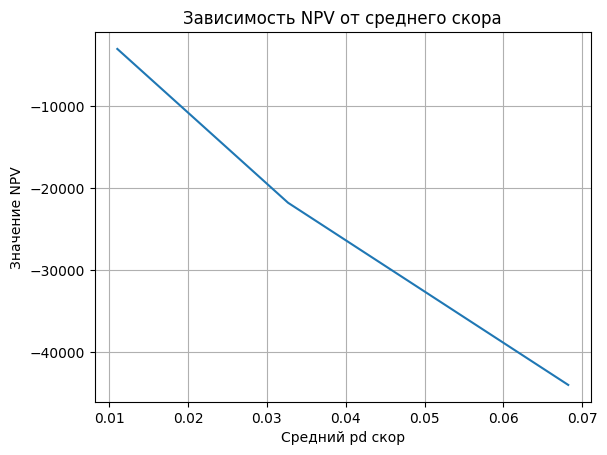

In [23]:
res = []
for x in sorted(buckets):
    res.append(npv_model.npv_calc(amount = 1_000_000, rate = 0.21, term = 24, def_curve=df_smooth_result, pd = x))

plt.plot(df_scores.groupby(["pd_bucket"])["pd"].mean(), res)
plt.title("Зависимость NPV от среднего скора")
plt.xlabel("Средний pd скор")
plt.ylabel('Значение NPV')
plt.grid()
plt.show()